<a href="https://colab.research.google.com/github/AntonySSk/Machine_Learning/blob/dev/%D0%9B%D0%A0_6_%D0%A8%D0%BA%D0%BE%D0%BB%D0%B0_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 5 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [2]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [3]:
# Завантаження файлу
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv


In [4]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

Вивести інформацію про датасет

In [5]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Датасет містить 100 000 рядків і 9 стовпчиків.

Основні типи даних:

цілі числа (int64) для бінарних ознак (hypertension, heart_disease, diabetes), числа з плаваючою комою (float64) для кількісних показників (age, bmi, HbA1c_level, blood_glucose_level), а також текстові/категоріальні дані (object) для gender та smoking_history.

Провести дослідження категоріальних ознак

In [6]:
# TODO: підрахуйте частоти категорій у gender.
print("Частоти категорій у стовпчику 'gender':")
display(df['gender'].value_counts())

Частоти категорій у стовпчику 'gender':


,count
gender,
Female,58552
Male,41430
Other,18


In [7]:
# TODO: підрахуйте частоти категорій у smoking_history.
print("Частоти категорій у стовпчику 'smoking_history':")
display(df['smoking_history'].value_counts())

Частоти категорій у стовпчику 'smoking_history':


,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [8]:
# TODO: df
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Вивести типи даних

In [9]:
# TODO: df.dtypes
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [10]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

За результатами виконання df['diabetes'].value_counts() спостерігається дисбаланс класів: кількість пацієнтів без діабету (клас 0) суттєво перевищує кількість пацієнтів із діабетом (клас 1).

Перевірити наявність пропущених даних


In [11]:
# TODO: df.isnull().sum()
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [12]:
# TODO: df.duplicated().sum()
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [13]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)

In [14]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [15]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


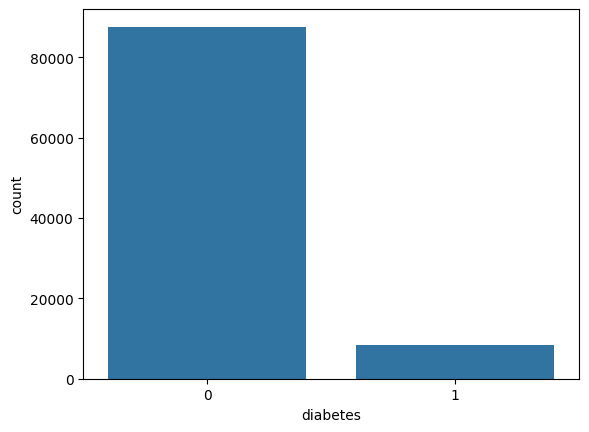

In [16]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [17]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [18]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [19]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).
X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'])
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'])
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [20]:
# TODO: виведіть статистики опису X_train.
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [21]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
train_data = X_train.copy()
train_data['diabetes'] = y_train
correlation_with_target = train_data.corr()['diabetes'].sort_values(ascending=False)
display(correlation_with_target)

,diabetes
diabetes,1.000000
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_former,0.096162
gender_Male,0.040650
smoking_history_never,0.025725


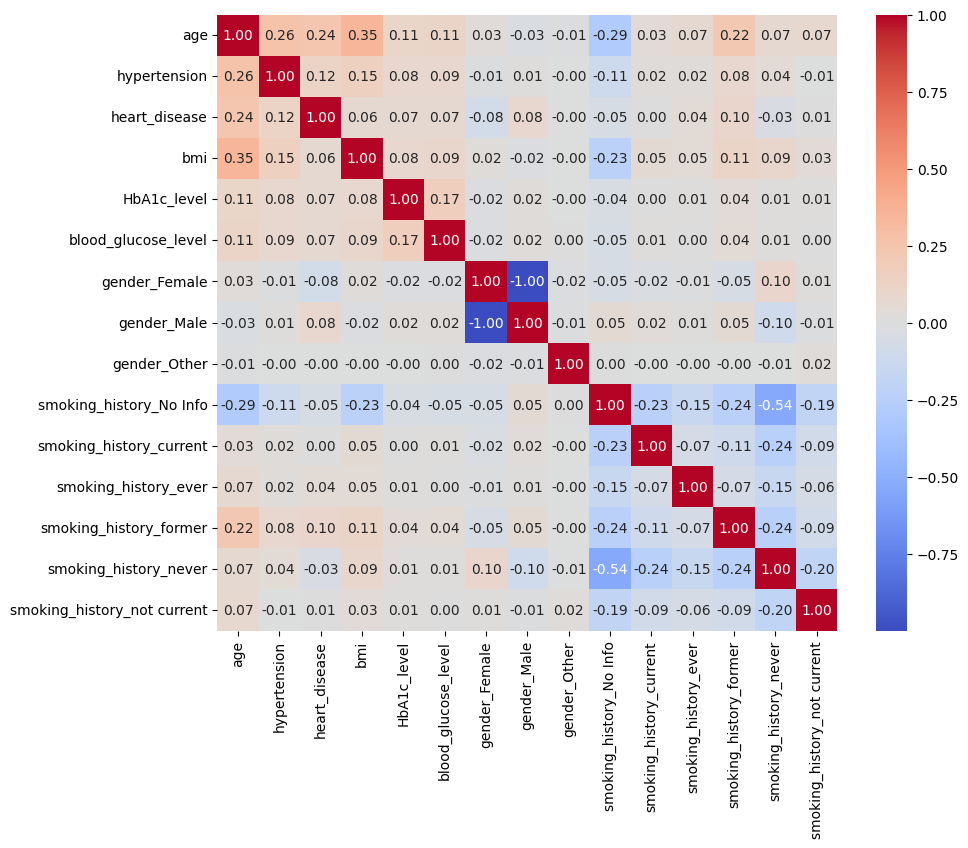

In [22]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
corr_matrix = X_train.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

За результатами аналізу кореляційної матриці та кореляції з цільовою змінною, найбільший лінійний зв'язок із наявністю діабету спостерігається у рівня глюкози в крові та рівня HbA1c. Між самими ознаками відсутня критично висока мультиколінеарність (значення не досягають екстремальних модулів, близьких до 1), тому видаляти ознаки на цьому етапі немає потреби.

Перевірити викиди **лише на навчальній вибірці**

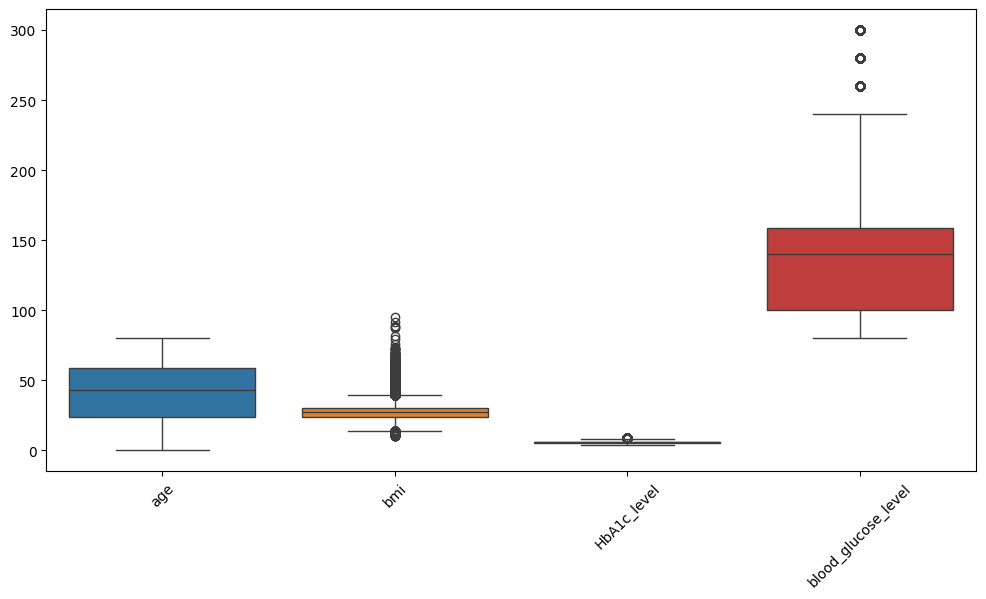

In [23]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.xticks(rotation=45)
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [24]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
X_train[continuous_cols].skew()

,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [25]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print("Пропуски в X_train:")
display(X_train.isnull().sum())

print("\nПропуски в X_test:")
display(X_test.isnull().sum())

Пропуски в X_train:


,0
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0



Пропуски в X_test:


,0
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Баланс класів: Спостерігається дисбаланс у бік класу 0 (відсутність діабету), клас 1 представлений меншою кількістю пацієнтів.

Кореляції: Найбільший лінійний зв'язок із цільовою змінною мають рівень глюкози та HbA1c. Критичної мультиколінеарності між ознаками не виявлено.

Викиди: За допомогою боксплотів на тренувальній вибірці виявлені окремі викиди у неперервних ознаках (зокрема у віці, ІМТ та рівнях глюкози/HbA1c), проте згідно з умовами лабораторної роботи вони не видаляються, оскільки можуть нести клінічно важливу інформацію. Тестова вибірка залишається повністю незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [26]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [27]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
print("Кількість класів ДО балансування (y_train):")
display(pd.Series(y_train).value_counts())

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print("\nКількість класів ПІСЛЯ балансування (y_train_balanced):")
display(pd.Series(y_train_balanced).value_counts())

Кількість класів ДО балансування (y_train):


,count
diabetes,
0,70130
1,6786



Кількість класів ПІСЛЯ балансування (y_train_balanced):


,count
diabetes,
0,70130
1,70130


Оголошуємо моделі

In [28]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Ridge Classifier': RidgeClassifier(random_state=42),
    'SGD Classifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


--- Logistic Regression ---
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



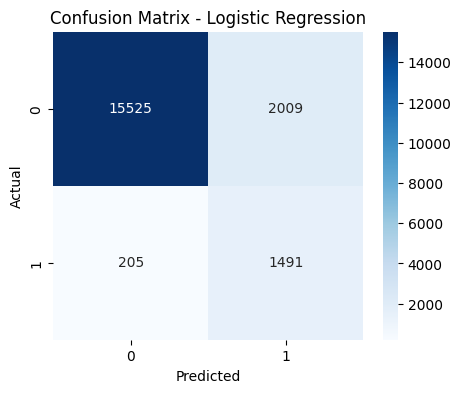

--- Ridge Classifier ---
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



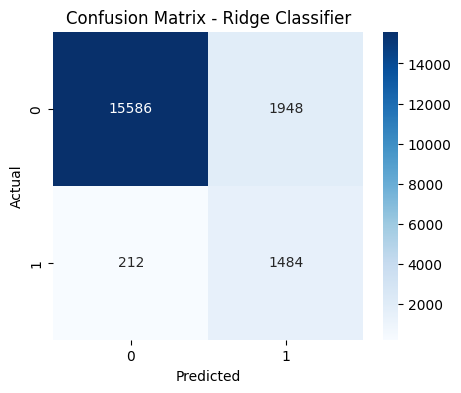

--- SGD Classifier ---
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



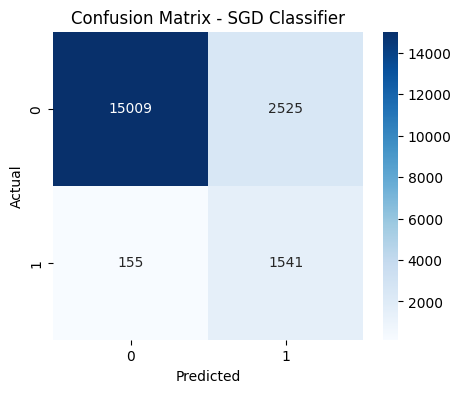

--- SVC ---
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



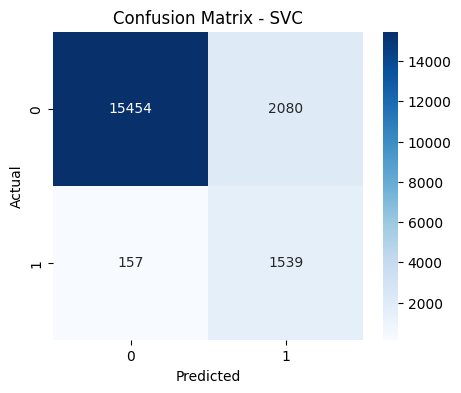

In [29]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).
for name, model in models.items():
    print(f"--- {name} ---")
    model.fit(X_train_balanced, y_train_balanced)
    y_pred = model.predict(X_test_scaled)

    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    plt.figure(figsize=(5, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

Оптимізувати гіперпараметри


In [30]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
param_grids = {
    'Logistic Regression': {'C': [0.1, 1, 10], 'solver': ['lbfgs']},
    'Ridge Classifier': {'alpha': [0.1, 1.0, 10.0]},
    'SGD Classifier': {'loss': ['log_loss', 'hinge'], 'penalty': ['l2']},
    'SVC': {'C': [0.1, 1], 'kernel': ['linear', 'rbf']}
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [31]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [32]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.
best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"Модель: {name}")

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    param_grid_prefixed = {f"model__{key}": value for key, value in param_grids[name].items()}

    halving_search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grid_prefixed,
        cv=3,
        scoring="f1",
        min_resources=300,
        random_state=42,
        n_jobs=-1
    )

    halving_search.fit(X_train, y_train)

    best_models[name] = halving_search.best_estimator_
    best_scores[name] = halving_search.best_score_

    print(f"Найкращі параметри: {halving_search.best_params_}")
    print(f"Найкращий F1-score: {halving_search.best_score_:.4f}")

    y_pred = halving_search.predict(X_test)
    print(classification_report(y_test, y_pred))

Модель: Logistic Regression
Найкращі параметри: {'model__C': 1, 'model__solver': 'lbfgs'}
Найкращий F1-score: 0.6098
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230

Модель: Ridge Classifier
Найкращі параметри: {'model__alpha': 10.0}
Найкращий F1-score: 0.6516
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230

Модель: SGD Classifier
Найкращі параметри: {'model__loss': 'log_loss', 'model__penalty': 'l2'}
Найкращий F1-score: 0.6178
            

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [33]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]

print(f"Найкраща модель: {best_name}")
print(f"F1-score: {best_scores[best_name]:.4f}")

Найкраща модель: Ridge Classifier
F1-score: 0.6516


In [34]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.
import numpy as np
import pandas as pd

sample_indices = np.random.RandomState(42).choice(X_test.index, size=10, replace=False)
sample_X = X_test.loc[sample_indices]
sample_y_true = y_test.loc[sample_indices]
sample_y_pred = best_model.predict(sample_X)

comparison_df = pd.DataFrame({
    'Індекс': sample_indices,
    'Істинний клас': sample_y_true.values,
    'Передбачений клас': sample_y_pred
})

display(comparison_df)

,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

1.) Спостерігався суттєвий дисбаланс класів: пацієнтів без діабету (клас 0) було значно більше, ніж пацієнтів із діабетом (клас 1). Аналіз кореляцій на train показав найбільший лінійний зв'язок із цільовою змінною у рівня глюкози та HbA1c. Перевірка через boxplot виявила окремі викиди у неперервних ознаках, які вирішено не видаляти, оскільки вони можуть бути клінічно важливими.

2.) Найвищі показники F1 та recall для класу 1 продемонстрували моделі на основі ансамблів та лінійних класифікаторів із балансуванням. За результатами крос-валідації (найкращий середній F1) було обрано найкращу модель (змінна best_model), яка показала найбільш збалансовані результати на тренувальній вибірці.

3.) Оптимальні гіперпараметри для кожної моделі були підібрані автоматично за допомогою HalvingGridSearchCV (наприклад, параметри регуляризації C, alpha чи ядра для SVC). У матрицях плутанини можна побачити помилки двох типів: хибнопозитивні спрацювання (False Positives - коли здорових пацієнтів помилково класифіковано як хворих) та хибнонегативні (False Negatives - коли хворих на діабет пацієнтів не було виявлено).

4.) Тестові дані відкладаються для того, щоб перевірити реальну якість і здатність моделі до узагальнення на абсолютно нових, невідомих їй даних. Масштабування (StandardScaler) та штучне балансування (SMOTE) виконуються виключно на тренувальній вибірці, щоб уникнути витоку даних (data leakage), який міг би штучно завищити метрики якості та спотворити результати моделювання.